In [1]:
import logging
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.metrics.pairwise import euclidean_distances, rbf_kernel
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from _utilities.stupidloggen import StupidLogGenerator

ROOT_DIR = os.environ["VIRTUAL_ENV"][:-5]
sys.path.append(ROOT_DIR)

In [2]:
PATH_REAL_DATA = "data/preprocessed_real_data.csv"
PATH_SYNTHETIC_DATA = "data/synthetic/"
PATH_FOLDER_MODELS = "models/"

In [3]:
logger = StupidLogGenerator.initLogger()

In [4]:
# Real Dataset
real_df = pd.read_csv(PATH_REAL_DATA)

# Target Column
target_feature = "is_recid"

# Sensitive Column
sensitive_feature = "sex"

# Synthetic Datasets
synthetic_datasets = {}

# Leak Columnc
LEAK_COLS = ["r_charge_degree", "two_year_recid"]

X_real = real_df.drop(columns=[target_feature] + LEAK_COLS)
CATEGORICAL_COLS = X_real.select_dtypes(include=["object"]).columns.tolist()
NUMERICAL_COLS = X_real.select_dtypes(exclude=["object"]).columns.tolist()
FEATURE_ORDER = X_real.columns.tolist()

# All tables
evaluation_results = []

In [5]:
# Load synthetic datasets
dir_list = os.listdir(PATH_SYNTHETIC_DATA)

for file_name in dir_list:
    model_name = file_name.replace("_synthetic.csv", "").replace("lambda_", "")
    synthetic_datasets[model_name] = pd.read_csv(PATH_SYNTHETIC_DATA + file_name)

## Downstream Classifier

### Preprocessing

In [6]:
real_train_df, real_test_df = train_test_split(real_df, test_size=0.2, random_state=42)


def build_pipeline(categorical_cols: list[str], numerical_cols: list[str]) -> Pipeline:
    """Builds a preprocessing + Logistic Regression pipeline"""

    preprocessor = ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
            ("num", "passthrough", numerical_cols),
        ]
    )

    pipeline = Pipeline(
        [
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(max_iter=1000)),
        ]
    )

    return pipeline

### Train the classifier

In [7]:
def train_pipeline(
    train_df: pd.DataFrame,
    target_col: str,
    categorical_cols: list[str],
    numeric_cols: list[str],
    feature_order: list[str],
) -> Pipeline:
    """Trains a pipeline on a given dataset."""

    X_train = train_df.drop(columns=[target_col])
    y_train = train_df[target_col]

    X_train = X_train.reindex(columns=feature_order)

    pipeline = build_pipeline(categorical_cols, numeric_cols)
    pipeline.fit(X_train, y_train)

    return pipeline

### Run the training on the real dataset and the synthetic dataset 

In [8]:
# Train on the real dataset
real_model = train_pipeline(
    real_train_df, target_feature, CATEGORICAL_COLS, NUMERICAL_COLS, FEATURE_ORDER
)

synthetic_models = {}
one_class_datasets = []

# Train synthetic models
for model_name, df in synthetic_datasets.items():
    n_unique = df[target_feature].nunique()

    if n_unique < 2:
        logger.warning(f"Skipping {model_name}: Found only {n_unique} class")

    try:
        synthetic_models[model_name] = train_pipeline(
            df, target_feature, CATEGORICAL_COLS, NUMERICAL_COLS, FEATURE_ORDER
        )
        logger.info(f"Successfully trained: {model_name}")
    except Exception as e:
        logger.error(f"Failed to train {model_name}: {e}")

[INFO]: Successfully trained: ctgan
[INFO]: Successfully trained: FairGAN_0.0
[WARNING]: Skipping FairGAN_0.1: Found only 1 class
[ERROR]: Failed to train FairGAN_0.1: This solver needs samples of at least 2 classes in the data, but the data contains only one class: np.int64(1)
[WARNING]: Skipping FairGAN_0.5: Found only 1 class
[ERROR]: Failed to train FairGAN_0.5: This solver needs samples of at least 2 classes in the data, but the data contains only one class: np.int64(1)
[INFO]: Successfully trained: FairGAN_0.7
[INFO]: Successfully trained: FairGAN_1.0
[INFO]: Successfully trained: TabFairGAN_0.0
[INFO]: Successfully trained: TabFairGAN_0.1
[INFO]: Successfully trained: TabFairGAN_0.5
[INFO]: Successfully trained: TabFairGAN_0.7
[INFO]: Successfully trained: TabFairGAN_1.0
[INFO]: Successfully trained: tvae


## Evaluation Definitions

#### Fairness Metrics

In [9]:
# Fairness Metrics Definition
# Note to self: Always sort groups first since order isn't guaranteed i.e. results may flip


def demographic_parity(y_pred: pd.Series, sensitive: pd.Series) -> float:
    groups = sorted(sensitive.unique())
    rates = [y_pred[sensitive == g].mean() for g in groups]
    return abs(rates[0] - rates[1])


def disparate_impact(y_pred: pd.Series, sensitive: pd.Series) -> float:
    groups = sorted(sensitive.unique())
    rate_0 = y_pred[sensitive == groups[0]].mean()
    rate_1 = y_pred[sensitive == groups[1]].mean()
    return min(rate_0 / (rate_1 + 1e-6), rate_1 / (rate_0 + 1e-6))


def equal_opportunity(
    y_true: pd.Series, y_pred: pd.Series, sensitive: pd.Series
) -> float:
    groups = sorted(sensitive.unique())
    tprs = []

    for g in groups:
        mask = sensitive == g
        tp = ((y_pred == 1) & (y_true == 1) & mask).sum()
        fn = ((y_pred == 0) & (y_true == 1) & mask).sum()
        tprs.append(tp / (tp + fn + 1e-6))

    return abs(tprs[0] - tprs[1])


def equalized_odds(y_true: pd.Series, y_pred: pd.Series, sensitive: pd.Series) -> float:
    groups = sorted(sensitive.unique())
    tpr_list, fpr_list = [], []

    for g in groups:
        mask = sensitive == g

        tp = ((y_pred == 1) & (y_true == 1) & mask).sum()
        fn = ((y_pred == 0) & (y_true == 1) & mask).sum()
        fp = ((y_pred == 1) & (y_true == 0) & mask).sum()
        tn = ((y_pred == 0) & (y_true == 0) & mask).sum()

        tpr = tp / (tp + fn + 1e-6)
        fpr = fp / (fp + tn + 1e-6)

        tpr_list.append(tpr)
        fpr_list.append(fpr)

    return abs(tpr_list[0] - tpr_list[1]) + abs(fpr_list[0] - fpr_list[1])


# Fairness Metrics Evaluation
def evaluate_fairness(
    model: Pipeline, test_df: pd.DataFrame, target_col: str, sensitive_col: str
) -> dict:
    """
    Evaluates fairness metrics on the real test set.
    """

    # Split test data
    X_test = test_df.drop(columns=[target_col])
    y_true = test_df[target_col]
    sensitive = test_df[sensitive_col]

    # Predict using trained pipeline
    y_pred = model.predict(X_test)
    y_pred = pd.Series(y_pred, index=X_test.index)

    # Compute fairness metrics
    results = {
        "demographic_parity": demographic_parity(y_pred, sensitive),
        "disparate_impact": disparate_impact(y_pred, sensitive),
        "equal_opportunity": equal_opportunity(y_true, y_pred, sensitive),
        "equalized_odds": equalized_odds(y_true, y_pred, sensitive),
    }

    return results

In [10]:
# Comparison of Fairness Across Datasets
fairness_results = {}

# Real dataset baseline
fairness_results["Real"] = evaluate_fairness(
    real_model,
    real_test_df,
    target_col=target_feature,
    sensitive_col=sensitive_feature,
)

# Synthetic models
for name, model in synthetic_models.items():
    fairness_results[name] = evaluate_fairness(
        model, real_test_df, target_col=target_feature, sensitive_col=sensitive_feature
    )

fairness_df = pd.DataFrame(fairness_results).T
evaluation_results.append(fairness_df)
fairness_df

,demographic_parity,disparate_impact,equal_opportunity,equalized_odds
Real,0.326213,0.375325,3.536643e-01,6.019453e-01
ctgan,0.120168,0.799775,6.950355e-02,1.615842e-01
FairGAN_0.0,0.036882,0.963117,3.723403e-02,7.380001e-02
FairGAN_0.7,0.070454,0.926914,1.364066e-01,1.449022e-01
FairGAN_1.0,0.000000,0.999999,9.338061e-09,1.399824e-08
TabFairGAN_0.0,0.160567,0.657322,1.463357e-01,2.629295e-01
TabFairGAN_0.1,0.407316,0.203396,5.043735e-01,7.962952e-01
TabFairGAN_0.5,0.497904,0.000000,6.684397e-01,1.013432e+00
TabFairGAN_0.7,0.547360,0.000000,7.127660e-01,1.111812e+00
TabFairGAN_1.0,0.582565,0.000000,7.180851e-01,1.179134e+00


#### Synthetic Data Realism Metric

In [11]:
def estimate_gamma(X: np.ndarray) -> float:
    """
    Estimates gamma using the median heuristic.
    """
    dists = euclidean_distances(X, X)
    dists = dists[dists > 0]  # remove zeros (distance to itself)

    median_dist = np.median(dists)

    gamma = 1 / (2 * (median_dist**2 + 1e-6))
    return gamma


# Preprocessing for MMD
def preprocess_mmd(df: pd.DataFrame, target_col: str) -> pd.DataFrame:
    """
    Converts dataframe into numeric matrix for MMD:
    - Drops target column
    - One-hot encodes categorical features
    """
    X = df.drop(columns=[target_col])
    X = pd.get_dummies(X, drop_first=True)
    return X


# MMD Computation
def compute_mmd(X_real: np.ndarray, X_synth: np.ndarray, gamma=1.0) -> float:
    """
    Computes Maximum Mean Discrepancy using RBF kernel.
    """
    K_xx = rbf_kernel(X_real, X_real, gamma=gamma)
    K_yy = rbf_kernel(X_synth, X_synth, gamma=gamma)
    K_xy = rbf_kernel(X_real, X_synth, gamma=gamma)

    mmd = K_xx.mean() + K_yy.mean() - 2 * K_xy.mean()

    return mmd


# Main Evaluation Function
def evaluate_realism(
    real_df: pd.DataFrame, synth_df: pd.DataFrame, target_col: str, sample_size=1000
) -> float:
    """
    Computes MMD using random sampling + median heuristic for gamma.
    """
    X_real = preprocess_mmd(real_df, target_col)
    X_synth = preprocess_mmd(synth_df, target_col)

    X_synth = X_synth.reindex(columns=X_real.columns, fill_value=0)

    # --- SAMPLE ---
    X_real_sample = X_real.sample(n=min(sample_size, len(X_real)), random_state=42)
    X_synth_sample = X_synth.sample(n=min(sample_size, len(X_synth)), random_state=42)

    # --- Estimate gamma from REAL data ---
    gamma = estimate_gamma(X_real_sample.values)

    return compute_mmd(
        X_real_sample.values,
        X_synth_sample.values,
        gamma=gamma,
    )

In [12]:
# Run for All Synthetic Datasets
realism_results = {}

for model_name, synth_df in synthetic_datasets.items():
    realism_results[model_name] = evaluate_realism(
        real_train_df, synth_df, target_col=target_feature, sample_size=1000
    )

realism_df = pd.DataFrame.from_dict(realism_results, orient="index", columns=["MMD"])
evaluation_results.append(realism_df)
realism_df

,MMD
ctgan,0.005589
FairGAN_0.0,0.920901
FairGAN_0.1,0.793877
FairGAN_0.5,0.228143
FairGAN_0.7,0.857435
FairGAN_1.0,1.034530
TabFairGAN_0.0,0.012250
TabFairGAN_0.1,0.011102
TabFairGAN_0.5,0.010953
TabFairGAN_0.7,0.012465


#### Utility

In [13]:
def evaluate_utility(model: Pipeline, test_df: pd.DataFrame, target_col: str) -> dict:
    """
    Evaluates predictive performance using TSTR:
    Train on (real/synthetic) → Test on REAL test data
    """
    X_test = test_df.drop(columns=[target_col])
    y_true = test_df[target_col]
    y_pred = model.predict(X_test)

    # Probabilities
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = y_pred

    results = {
        "accuracy": accuracy_score(y_true, y_pred),
        "auc": roc_auc_score(y_true, y_prob),
    }

    return results

In [14]:
utility_results = {}

# Real dataset baseline
utility_results["Real"] = evaluate_utility(
    real_model, real_test_df, target_col=target_feature
)

# Synthetic models
for model_name, model in synthetic_models.items():
    utility_results[model_name] = evaluate_utility(
        model, real_test_df, target_col=target_feature
    )

utility_df = pd.DataFrame(utility_results).T
utility_df

,accuracy,auc
Real,0.679834,0.734520
ctgan,0.656272,0.729804
FairGAN_0.0,0.454608,0.634480
FairGAN_0.7,0.400554,0.329303
FairGAN_1.0,0.453222,0.731489
TabFairGAN_0.0,0.653500,0.696065
TabFairGAN_0.1,0.671518,0.729888
TabFairGAN_0.5,0.657658,0.683251
TabFairGAN_0.7,0.651421,0.679869
TabFairGAN_1.0,0.626473,0.668671


## Evaluation Comparison

In [15]:
logger.setLevel(logging.INFO)

In [16]:
sort_order = [
    "Real",
    "ctgan",
    "tvae",
    "FairGAN_0.0",
    "FairGAN_0.1",
    "FairGAN_0.5",
    "FairGAN_0.7",
    "FairGAN_1.0",
    "TabFairGAN_0.0",
    "TabFairGAN_0.1",
    "TabFairGAN_0.5",
    "TabFairGAN_0.7",
    "TabFairGAN_1.0",
]

final_df = pd.concat([utility_df, fairness_df, realism_df], axis=1)
final_df = final_df.reindex(sort_order)
final_df = final_df.fillna("-")

final_df = final_df[
    [
        "accuracy",
        "auc",
        "demographic_parity",
        "disparate_impact",
        "equal_opportunity",
        "equalized_odds",
        "MMD",
    ]
]
final_df

model_labels = []

for model_name in final_df.index:
    if model_name == "Real":
        model_labels.append("Real")
    elif "FairGAN" in model_name:
        model_name_parts = model_name.split("_")
        model_labels.append(f"{model_name_parts[0]} (λ={model_name_parts[1]})")
    else:
        model_labels.append(model_name.upper())

final_df = final_df.rename(index=dict(zip(final_df.index, model_labels)))
final_df


,accuracy,auc,demographic_parity,disparate_impact,equal_opportunity,equalized_odds,MMD
Real,0.679834,0.73452,0.326213,0.375325,0.353664,0.601945,-
CTGAN,0.656272,0.729804,0.120168,0.799775,0.069504,0.161584,0.005589
TVAE,0.613999,0.658666,0.525036,0.043713,0.620449,1.0531,0.007341
FairGAN (λ=0.0),0.454608,0.63448,0.036882,0.963117,0.037234,0.0738,0.920901
FairGAN (λ=0.1),-,-,-,-,-,-,0.793877
FairGAN (λ=0.5),-,-,-,-,-,-,0.228143
FairGAN (λ=0.7),0.400554,0.329303,0.070454,0.926914,0.136407,0.144902,0.857435
FairGAN (λ=1.0),0.453222,0.731489,0.0,0.999999,0.0,0.0,1.03453
TabFairGAN (λ=0.0),0.6535,0.696065,0.160567,0.657322,0.146336,0.26293,0.01225
TabFairGAN (λ=0.1),0.671518,0.729888,0.407316,0.203396,0.504374,0.796295,0.011102


# Graphs

In [17]:
metric_cols = [
    "accuracy",
    "auc",
    "demographic_parity",
    "disparate_impact",
    "equal_opportunity",
    "equalized_odds",
    "MMD",
]
final_df[metric_cols] = final_df[metric_cols].apply(pd.to_numeric, errors="coerce")

os.makedirs("figures", exist_ok=True)

## Statistical realism (MMD)

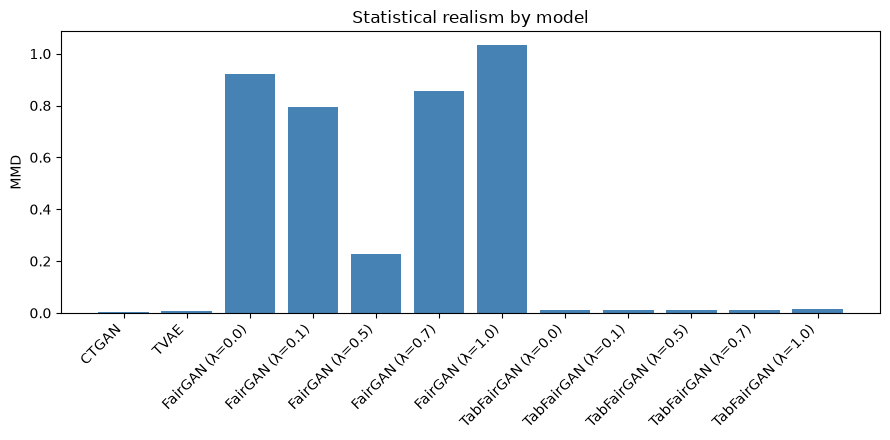

In [18]:
mmd_data = final_df["MMD"].dropna()

plt.figure(figsize=(9, 4.5))
plt.bar(mmd_data.index, mmd_data.values, color="steelblue")
plt.ylabel("MMD")
plt.title("Statistical realism by model")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("figures/stat_realism_mmd.png")
plt.show()

## Predictive utility (accuracy + AUC)

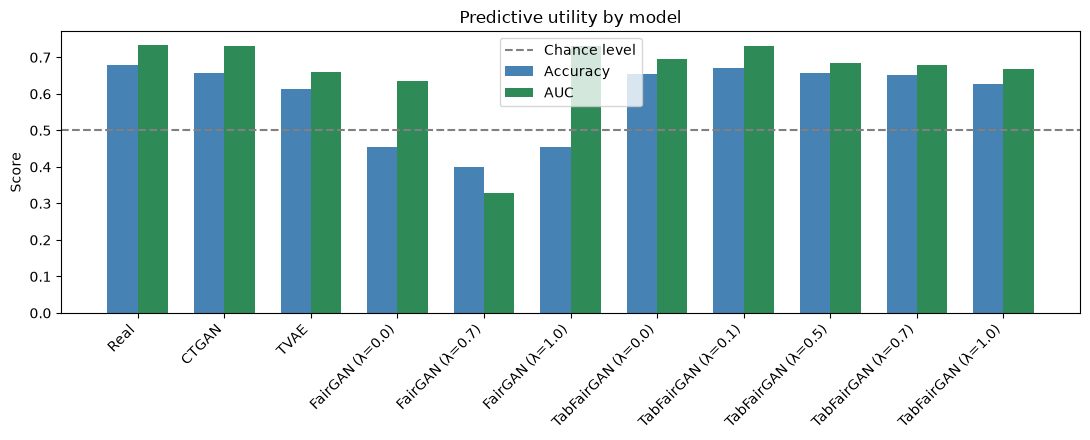

In [19]:
utility_data = final_df[["accuracy", "auc"]].dropna()
model_names = utility_data.index
x_positions = np.arange(len(model_names))
bar_width = 0.35

plt.figure(figsize=(11, 4.5))
plt.bar(
    x_positions - bar_width / 2,
    utility_data["accuracy"],
    bar_width,
    label="Accuracy",
    color="steelblue",
)
plt.bar(
    x_positions + bar_width / 2,
    utility_data["auc"],
    bar_width,
    label="AUC",
    color="seagreen",
)
plt.axhline(0.5, color="gray", linestyle="--", label="Chance level")
plt.xticks(x_positions, model_names, rotation=45, ha="right")
plt.ylabel("Score")
plt.title("Predictive utility by model")
plt.legend()
plt.tight_layout()
plt.savefig("figures/predictive_utility.png")
plt.show()

## Trade-off across λ (FairGAN and TabFairGAN)

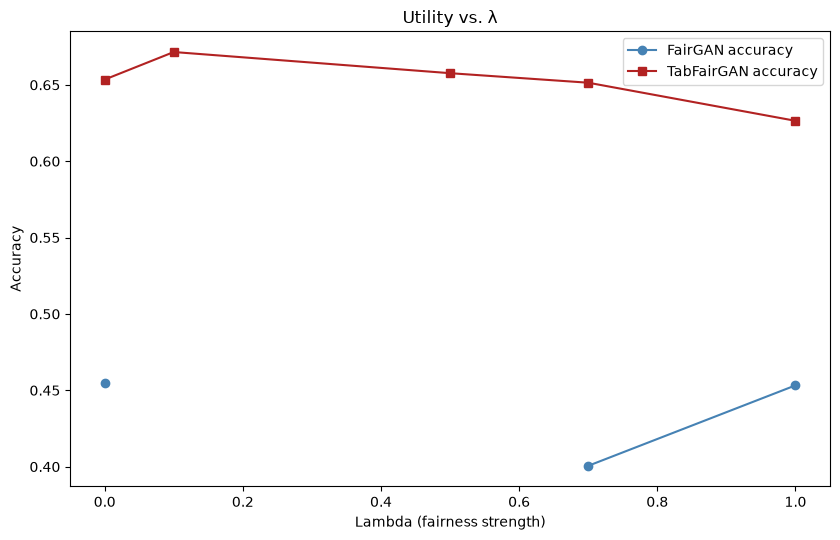

In [20]:
fairgan_labels = [x for x in final_df.index if "FairGAN" in x and "Tab" not in x]
fairgan_lambdas = [0.0, 0.1, 0.5, 0.7, 1.0]

tabfairgan_labels = [x for x in final_df.index if "TabFairGAN" in x]
tabfairgan_lambdas = [0.0, 0.1, 0.5, 0.7, 1.0]

fairgan_accuracy = final_df.loc[fairgan_labels, "accuracy"]
tabfairgan_accuracy = final_df.loc[tabfairgan_labels, "accuracy"]

fig, ax1 = plt.subplots(figsize=(8.5, 5.5))
ax1.plot(
    fairgan_lambdas,
    fairgan_accuracy,
    marker="o",
    color="steelblue",
    label="FairGAN accuracy",
)
ax1.plot(
    tabfairgan_lambdas,
    tabfairgan_accuracy,
    marker="s",
    color="firebrick",
    label="TabFairGAN accuracy",
)
ax1.set_xlabel("Lambda (fairness strength)")
ax1.set_ylabel("Accuracy")
ax1.set_title("Utility vs. λ")
ax1.legend()
plt.tight_layout()
plt.savefig("figures/lambda_tradeoff.png")
plt.show()


## Fairness metrics

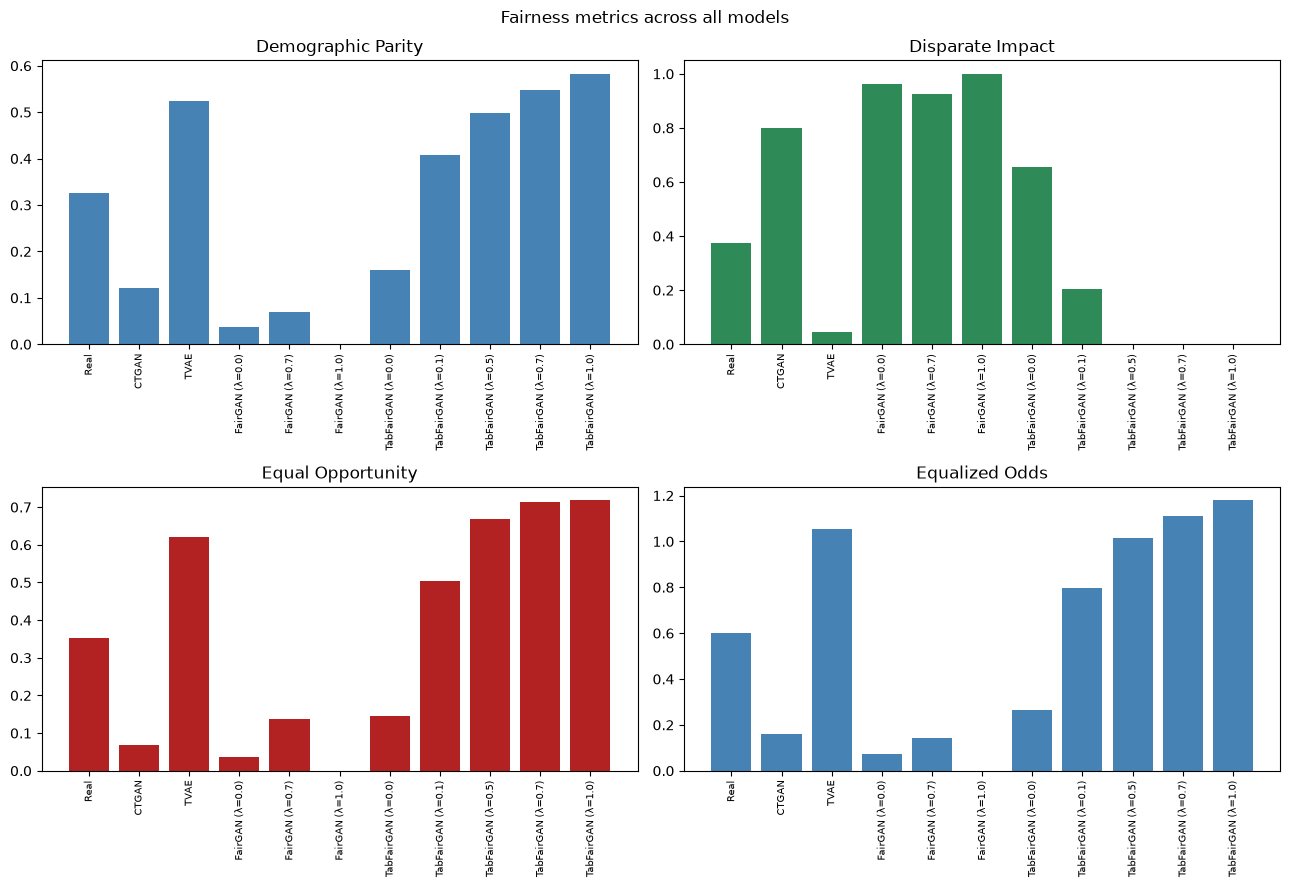

In [ ]:
fairness_cols = [
    "demographic_parity",
    "disparate_impact",
    "equal_opportunity",
    "equalized_odds",
]

fairness_data = final_df[fairness_cols].dropna()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].bar(
    fairness_data.index, fairness_data["demographic_parity"], color="steelblue"
)
axes[0, 0].set_title("Demographic Parity")

axes[0, 1].bar(fairness_data.index, fairness_data["disparate_impact"], color="seagreen")
axes[0, 1].set_title("Disparate Impact")

axes[1, 0].bar(
    fairness_data.index, fairness_data["equal_opportunity"], color="firebrick"
)
axes[1, 0].set_title("Equal Opportunity")

axes[1, 1].bar(fairness_data.index, fairness_data["equalized_odds"], color="steelblue")
axes[1, 1].set_title("Equalized Odds")

for ax in axes.flat:
    ax.tick_params(axis="x", rotation=90, labelsize=7)

plt.suptitle("Fairness metrics across all models")
plt.tight_layout()
plt.savefig("figures/fairness_metrics.png")
plt.show()


In [35]:
def format_metric_names(metric: str) -> str:
    """
    Formats metric names for LaTeX table.
    """
    if len(metric) <= 3:
        return metric.upper()
    else:
        return metric.replace("_", " ").title()


def convert_lambda_to_latex(model_name: str) -> str:
    """
    Converts model names with lambda values to LaTeX format.
    """
    if "λ" in model_name:
        parts = model_name.split(" (λ=")
        base_name = parts[0]
        lambda_value = parts[1][:-1]  # Remove the closing parenthesis
        return f"{base_name} ($\\lambda={lambda_value}$)"
    else:
        return model_name


df_for_latex = final_df.copy()
df_for_latex = df_for_latex.rename(
    mapper={col: format_metric_names(col) for col in df_for_latex.columns},
    axis="columns",
)
df_for_latex = df_for_latex.rename(
    mapper={row: convert_lambda_to_latex(row) for row in df_for_latex.index},
    axis="rows",
)

latex_code = df_for_latex.to_latex(
    index=True,
    na_rep="-",
    caption="Results Table",
    label="tab:table_results",
    position="htbp",
    column_format=f"l{'c' * len(df_for_latex.columns)}",
    float_format="%.2f",
)

print(latex_code)
final_df

\begin{table}[htbp]
\caption{Results Table}
\label{tab:table_results}
\begin{tabular}{lccccccc}
\toprule
 & Accuracy & AUC & Demographic Parity & Disparate Impact & Equal Opportunity & Equalized Odds & MMD \\
\midrule
Real & 0.68 & 0.73 & 0.33 & 0.38 & 0.35 & 0.60 & - \\
CTGAN & 0.66 & 0.73 & 0.12 & 0.80 & 0.07 & 0.16 & 0.01 \\
TVAE & 0.61 & 0.66 & 0.53 & 0.04 & 0.62 & 1.05 & 0.01 \\
FairGAN ($\lambda=0.0$) & 0.45 & 0.63 & 0.04 & 0.96 & 0.04 & 0.07 & 0.92 \\
FairGAN ($\lambda=0.1$) & - & - & - & - & - & - & 0.79 \\
FairGAN ($\lambda=0.5$) & - & - & - & - & - & - & 0.23 \\
FairGAN ($\lambda=0.7$) & 0.40 & 0.33 & 0.07 & 0.93 & 0.14 & 0.14 & 0.86 \\
FairGAN ($\lambda=1.0$) & 0.45 & 0.73 & 0.00 & 1.00 & 0.00 & 0.00 & 1.03 \\
TabFairGAN ($\lambda=0.0$) & 0.65 & 0.70 & 0.16 & 0.66 & 0.15 & 0.26 & 0.01 \\
TabFairGAN ($\lambda=0.1$) & 0.67 & 0.73 & 0.41 & 0.20 & 0.50 & 0.80 & 0.01 \\
TabFairGAN ($\lambda=0.5$) & 0.66 & 0.68 & 0.50 & 0.00 & 0.67 & 1.01 & 0.01 \\
TabFairGAN ($\lambda=0.7$) & 0.6

,accuracy,auc,demographic_parity,disparate_impact,equal_opportunity,equalized_odds,MMD
Real,0.679834,0.734520,0.326213,0.375325,3.536643e-01,6.019453e-01,NaN
CTGAN,0.656272,0.729804,0.120168,0.799775,6.950355e-02,1.615842e-01,0.005589
TVAE,0.613999,0.658666,0.525036,0.043713,6.204492e-01,1.053100e+00,0.007341
FairGAN (λ=0.0),0.454608,0.634480,0.036882,0.963117,3.723403e-02,7.380001e-02,0.920901
FairGAN (λ=0.1),NaN,NaN,NaN,NaN,NaN,NaN,0.793877
FairGAN (λ=0.5),NaN,NaN,NaN,NaN,NaN,NaN,0.228143
FairGAN (λ=0.7),0.400554,0.329303,0.070454,0.926914,1.364066e-01,1.449022e-01,0.857435
FairGAN (λ=1.0),0.453222,0.731489,0.000000,0.999999,9.338061e-09,1.399824e-08,1.034530
TabFairGAN (λ=0.0),0.653500,0.696065,0.160567,0.657322,1.463357e-01,2.629295e-01,0.012250
TabFairGAN (λ=0.1),0.671518,0.729888,0.407316,0.203396,5.043735e-01,7.962952e-01,0.011102
